# Thyroid Cancer Prediction 


> This project predicts the dataset's `Diagnosis` label. It is not a clinical diagnostic system.

## 1. Imports

In [18]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

## 2. Load the dataset



In [ ]:
DATA_PATH = "data/Thyroid Cancer Dataset.csv"

data = pd.read_csv('Thyroid Cancer Dataset.csv')

print(f"Dataset shape: {data.shape}")
data.head()

Dataset shape: (212691, 18)


,Unnamed: 0,Patient_ID,Age,Gender,Country,Ethnicity,Family_History,Radiation_Exposure,Iodine_Deficiency,Smoking,Obesity,Diabetes,TSH_Level,T3_Level,T4_Level,Nodule_Size,Thyroid_Cancer_Risk,Diagnosis
0,0,1,66,Male,Russia,Caucasian,No,Yes,No,No,No,No,9.37,1.67,6.16,1.08,Low,Benign
1,1,2,29,Male,Germany,Hispanic,No,Yes,No,No,No,No,1.83,1.73,10.54,4.05,Low,Benign
2,2,3,86,Male,Nigeria,Caucasian,No,No,No,No,No,No,6.26,2.59,10.57,4.61,Low,Benign
3,3,4,75,Female,India,Asian,No,No,No,No,No,No,4.10,2.62,11.04,2.46,Medium,Benign
4,4,5,35,Female,Germany,African,Yes,Yes,No,No,No,No,9.10,2.11,10.71,2.11,High,Benign


## 3. Initial data inspection

In [20]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 212691 entries, 0 to 212690
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   Unnamed: 0           212691 non-null  int64  
 1   Patient_ID           212691 non-null  int64  
 2   Age                  212691 non-null  int64  
 3   Gender               212691 non-null  object 
 4   Country              212691 non-null  object 
 5   Ethnicity            212691 non-null  object 
 6   Family_History       212691 non-null  object 
 7   Radiation_Exposure   212691 non-null  object 
 8   Iodine_Deficiency    212691 non-null  object 
 9   Smoking              212691 non-null  object 
 10  Obesity              212691 non-null  object 
 11  Diabetes             212691 non-null  object 
 12  TSH_Level            212691 non-null  float64
 13  T3_Level             212691 non-null  float64
 14  T4_Level             212691 non-null  float64
 15  Nodule_Size      

In [21]:
print("Missing values by column:")
display(data.isna().sum())

print(f"\nDuplicated rows: {data.duplicated().sum()}")
print(f"Duplicated Patient_ID values: {data.duplicated(subset=["Patient_ID"]).sum()}")

Missing values by column:


Unnamed: 0             0
Patient_ID             0
Age                    0
Gender                 0
Country                0
Ethnicity              0
Family_History         0
Radiation_Exposure     0
Iodine_Deficiency      0
Smoking                0
Obesity                0
Diabetes               0
TSH_Level              0
T3_Level               0
T4_Level               0
Nodule_Size            0
Thyroid_Cancer_Risk    0
Diagnosis              0
dtype: int64


Duplicated rows: 0
Duplicated Patient_ID values: 0


In [22]:
display(data.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,212691.0,NaN,NaN,NaN,106345.0,61398.74739,0.0,53172.5,106345.0,159517.5,212690.0
Patient_ID,212691.0,NaN,NaN,NaN,106346.0,61398.74739,1.0,53173.5,106346.0,159518.5,212691.0
Age,212691.0,NaN,NaN,NaN,51.918497,21.632815,15.0,33.0,52.0,71.0,89.0
Gender,212691,2,Female,127527,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country,212691,12,India,42496,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ethnicity,212691,5,Caucasian,63669,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Family_History,212691,2,No,148866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Radiation_Exposure,212691,2,No,180831,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Iodine_Deficiency,212691,2,No,159673,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Smoking,212691,2,No,170260,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 4. Target distribution

The target is `Diagnosis`, with the classes `Benign` and `Malignant`.

,Count
Diagnosis,
Benign,163196
Malignant,49495


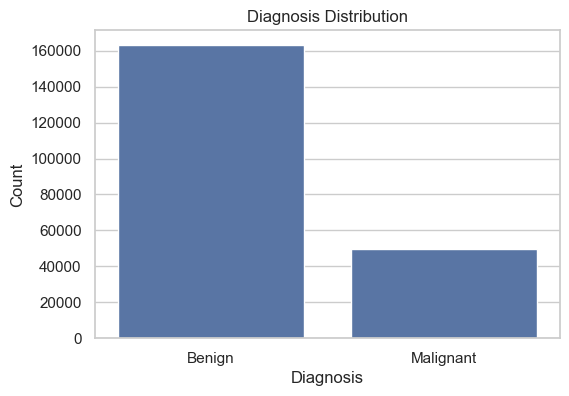

Class proportions:


,Proportion
Diagnosis,
Benign,0.7673
Malignant,0.2327


In [23]:
target_counts = data["Diagnosis"].value_counts()

display(target_counts.to_frame("Count"))

plt.figure(figsize=(6, 4))
sns.countplot(data=data, x="Diagnosis")
plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Count")
plt.show()

print("Class proportions:")
display((target_counts / len(data)).round(4).to_frame("Proportion"))

## 5. Basic EDA

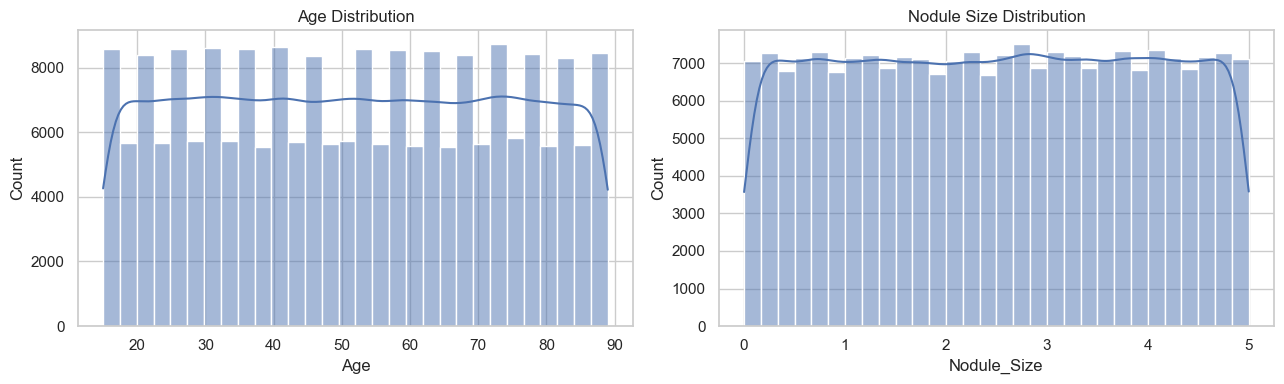

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sns.histplot(data=data, x="Age", bins=30, kde=True, ax=axes[0])
axes[0].set_title("Age Distribution")

sns.histplot(data=data, x="Nodule_Size", bins=30, kde=True, ax=axes[1])
axes[1].set_title("Nodule Size Distribution")

plt.tight_layout()
plt.show()

Diagnosis,Benign,Malignant
Thyroid_Cancer_Risk,,
High,0.300,0.700
Low,0.850,0.150
Medium,0.849,0.151


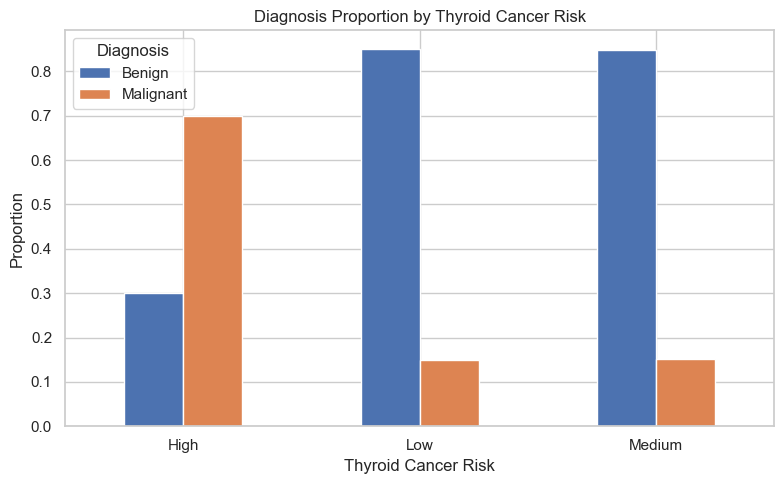

In [25]:
risk_diagnosis = pd.crosstab(
    data["Thyroid_Cancer_Risk"],
    data["Diagnosis"],
    normalize="index"
).round(3)

display(risk_diagnosis)

risk_diagnosis.plot(kind="bar", figsize=(8, 5))
plt.title("Diagnosis Proportion by Thyroid Cancer Risk")
plt.xlabel("Thyroid Cancer Risk")
plt.ylabel("Proportion")
plt.xticks(rotation=0)
plt.legend(title="Diagnosis")
plt.tight_layout()
plt.show()

## 6. Prepare features and target

`Unnamed: 0` and `Patient_ID` are identifiers and are removed from the predictive feature set.

The `Diagnosis` target is encoded as:

- `Benign` → 0
- `Malignant` → 1

In [26]:
TARGET = "Diagnosis"
ID_COLUMNS = ["Unnamed: 0", "Patient_ID"]

data_model = data.drop(columns=ID_COLUMNS).copy()

X = data_model.drop(columns=TARGET)
y = data_model[TARGET].map({"Benign": 0, "Malignant": 1})

if y.isna().any():
    raise ValueError("Unexpected values found in Diagnosis.")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)
print("\nTraining class distribution:")
print(y_train.value_counts(normalize=True).rename(index={0: "Benign", 1: "Malignant"}))

Training set: (170152, 15)
Test set: (42539, 15)

Training class distribution:
Diagnosis
Benign       0.76729
Malignant    0.23271
Name: proportion, dtype: float64


## 7. Preprocessing pipeline

This replaces the original manual `LabelEncoder` approach.

The encoder is fitted **only on the training data** through the pipeline. The same fitted transformation is then applied to the test data.

`handle_unknown="ignore"` prevents unseen categorical levels from causing errors when making predictions on new data.

In [27]:
categorical_cols = X_train.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X_train.select_dtypes(exclude=["object"]).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_cols,
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_cols,
        ),
    ]
)

Categorical columns: ['Gender', 'Country', 'Ethnicity', 'Family_History', 'Radiation_Exposure', 'Iodine_Deficiency', 'Smoking', 'Obesity', 'Diabetes', 'Thyroid_Cancer_Risk']
Numerical columns: ['Age', 'TSH_Level', 'T3_Level', 'T4_Level', 'Nodule_Size']


## 8. Define the models

Three models are compared:

1. Logistic Regression — a strong interpretable baseline.
2. Decision Tree — captures non-linear relationships.
3. Random Forest — an ensemble of decision trees and a stronger baseline for tabular data.

In [28]:
models = {
    "Logistic Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE
        )),
    ]),

    "Decision Tree": Pipeline([
        ("preprocessor", preprocessor),
        ("model", DecisionTreeClassifier(
            max_depth=8,
            min_samples_split=10,
            random_state=RANDOM_STATE
        )),
    ]),

    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestClassifier(
            n_estimators=100,
            max_depth=12,
            min_samples_split=10,
            random_state=RANDOM_STATE,
            n_jobs=-1
        )),
    ]),
}

## 9. Train and evaluate all models

In [29]:
def evaluate_model(model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    return {
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0),
    }, predictions


results = []
predictions = {}

for name, model in models.items():
    metrics, y_pred = evaluate_model(
        model, X_train, X_test, y_train, y_test
    )

    metrics["Model"] = name
    results.append(metrics)
    predictions[name] = y_pred

results_df = (
    pd.DataFrame(results)
    .set_index("Model")
    .sort_values("F1 Score", ascending=False)
)

display(results_df.round(4))

,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.8293,0.7066,0.4557,0.5541
Random Forest,0.8293,0.7066,0.4557,0.5541
Decision Tree,0.8283,0.7050,0.4503,0.5496


## 10. Visualize model comparison

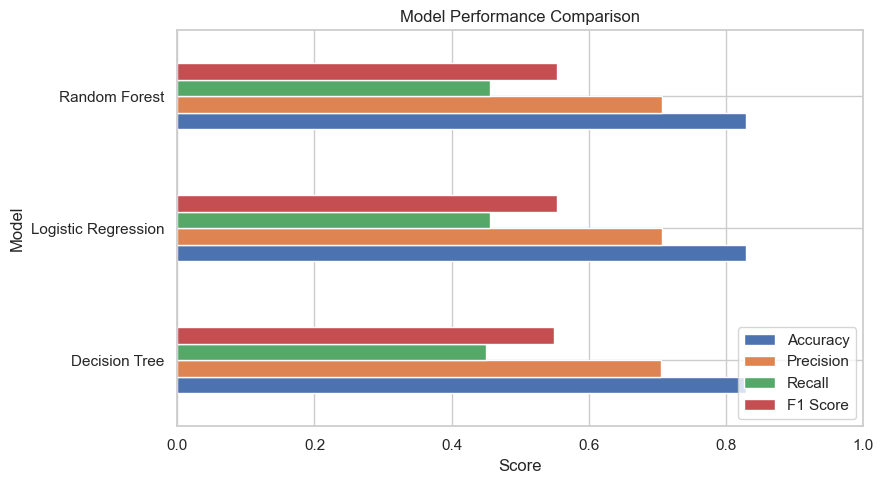

In [30]:
results_df.sort_values("F1 Score").plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Model Performance Comparison")
plt.xlabel("Score")
plt.xlim(0, 1)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

## 11. Confusion matrix and classification report

The model with the highest test-set F1 Score is selected for detailed inspection.

Best model by test F1 Score: Logistic Regression

              precision    recall  f1-score   support

      Benign       0.85      0.94      0.89     32640
   Malignant       0.71      0.46      0.55      9899

    accuracy                           0.83     42539
   macro avg       0.78      0.70      0.72     42539
weighted avg       0.82      0.83      0.82     42539



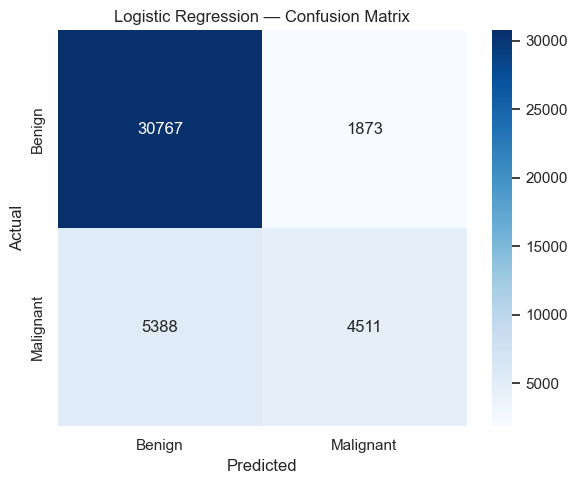

In [31]:
best_model_name = results_df.index[0]
best_predictions = predictions[best_model_name]

print(f"Best model by test F1 Score: {best_model_name}\n")

print(
    classification_report(
        y_test,
        best_predictions,
        target_names=["Benign", "Malignant"],
        zero_division=0,
    )
)

cm = confusion_matrix(y_test, best_predictions)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant"],
    yticklabels=["Benign", "Malignant"],
)

plt.title(f"{best_model_name} — Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 12. 5-fold cross-validation

Cross-validation gives a more robust estimate than relying on one train/test split.

F1 Score is used because it balances precision and recall.

In [32]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE
)

cv_rows = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1,
    )

    cv_rows.append({
        "Model": name,
        "Mean CV F1": scores.mean(),
        "Std CV F1": scores.std(),
    })

cv_results_df = (
    pd.DataFrame(cv_rows)
    .set_index("Model")
    .sort_values("Mean CV F1", ascending=False)
)

display(cv_results_df.round(4))

,Mean CV F1,Std CV F1
Model,,
Logistic Regression,0.5476,0.0032
Random Forest,0.5476,0.0032
Decision Tree,0.5429,0.0038


## 13. Important: investigate possible target leakage

`Thyroid_Cancer_Risk` is a feature in the source dataset. Because it is explicitly named as a cancer-risk assessment, we should check whether it may contain information derived from the diagnosis or from variables that would not be available at prediction time.

This notebook therefore compares:

- **Scenario A:** all available predictors, including `Thyroid_Cancer_Risk`
- **Scenario B:** predictors excluding `Thyroid_Cancer_Risk`

A large performance drop after removing this feature is a signal that it deserves further investigation. It is **not, by itself, proof of leakage**.

In [33]:
def build_preprocessor(X_reference):
    categorical = X_reference.select_dtypes(include=["object"]).columns.tolist()
    numerical = X_reference.select_dtypes(exclude=["object"]).columns.tolist()

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numerical),
            ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
        ]
    )


def run_scenario(include_risk_feature=True):
    scenario_data = data.drop(columns=ID_COLUMNS).copy()

    if not include_risk_feature:
        scenario_data = scenario_data.drop(columns=["Thyroid_Cancer_Risk"])

    X_s = scenario_data.drop(columns=TARGET)
    y_s = scenario_data[TARGET].map({"Benign": 0, "Malignant": 1})

    X_tr, X_te, y_tr, y_te = train_test_split(
        X_s,
        y_s,
        test_size=0.20,
        random_state=RANDOM_STATE,
        stratify=y_s,
    )

    prep = build_preprocessor(X_tr)

    scenario_models = {
        "Logistic Regression": Pipeline([
            ("preprocessor", prep),
            ("model", LogisticRegression(
                max_iter=1000,
                random_state=RANDOM_STATE
            )),
        ]),
        "Decision Tree": Pipeline([
            ("preprocessor", prep),
            ("model", DecisionTreeClassifier(
                max_depth=8,
                min_samples_split=10,
                random_state=RANDOM_STATE
            )),
        ]),
        "Random Forest": Pipeline([
            ("preprocessor", prep),
            ("model", RandomForestClassifier(
                n_estimators=100,
                max_depth=12,
                min_samples_split=10,
                random_state=RANDOM_STATE,
                n_jobs=-1
            )),
        ]),
    }

    rows = []

    for name, model in scenario_models.items():
        model.fit(X_tr, y_tr)
        pred = model.predict(X_te)

        rows.append({
            "Model": name,
            "Accuracy": accuracy_score(y_te, pred),
            "Precision": precision_score(y_te, pred, zero_division=0),
            "Recall": recall_score(y_te, pred, zero_division=0),
            "F1 Score": f1_score(y_te, pred, zero_division=0),
        })

    return pd.DataFrame(rows).set_index("Model")


with_risk_results = run_scenario(include_risk_feature=True)
without_risk_results = run_scenario(include_risk_feature=False)

print("WITH Thyroid_Cancer_Risk")
display(with_risk_results.round(4))

print("\nWITHOUT Thyroid_Cancer_Risk")
display(without_risk_results.round(4))

WITH Thyroid_Cancer_Risk


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.8293,0.7066,0.4557,0.5541
Decision Tree,0.8283,0.7050,0.4503,0.5496
Random Forest,0.8293,0.7066,0.4557,0.5541



WITHOUT Thyroid_Cancer_Risk


,Accuracy,Precision,Recall,F1 Score
Model,,,,
Logistic Regression,0.7806,0.7077,0.0976,0.1715
Decision Tree,0.8276,0.7045,0.4463,0.5464
Random Forest,0.8293,0.7066,0.4556,0.5540


## 14. Leakage comparison summary

In [34]:
comparison = pd.DataFrame({
    "With Risk Feature": with_risk_results["F1 Score"],
    "Without Risk Feature": without_risk_results["F1 Score"],
})

comparison["F1 Difference"] = (
    comparison["With Risk Feature"] -
    comparison["Without Risk Feature"]
)

display(comparison.sort_values("F1 Difference", ascending=False).round(4))

,With Risk Feature,Without Risk Feature,F1 Difference
Model,,,
Logistic Regression,0.5541,0.1715,0.3826
Decision Tree,0.5496,0.5464,0.0032
Random Forest,0.5541,0.5540,0.0001


### How to interpret the leakage test

Do **not** automatically remove `Thyroid_Cancer_Risk` just because performance changes.

Instead, document where that feature comes from:

- If it is calculated using information available **before** the target is known, it can potentially be a legitimate predictor.
- If it is calculated from the diagnosis itself, pathology, or another post-diagnosis assessment, it should be excluded because that would leak target information.

For a portfolio project, reporting both scenarios is a strong and transparent approach.

## 15. Final conclusions


- **Best model by test F1:** Logistic Regression and Random Forest (tied at 0.5541).

- **Best model by mean CV F1:** Logistic Regression and Random Forest (tied at 0.5476, with a standard deviation of 0.0032).

- **Main strengths:** Logistic Regression and Random Forest achieved the highest test F1 score (0.5541) and mean cross-validation F1 score (0.5476). Both models showed consistent cross-validation performance, with a low standard deviation of 0.0032. Random Forest also maintained nearly identical performance with and without the `Thyroid_Cancer_Risk` feature.

- **Main limitations:** The best-performing models achieved a recall of only 0.4557, meaning they failed to identify approximately 54.4% of actual positive cases. Logistic Regression's F1 score dropped substantially from 0.5541 to 0.1715 when `Thyroid_Cancer_Risk` was removed, indicating strong dependence on this feature. The Decision Tree performed slightly worse, with a mean CV F1 of 0.5429.

- **Decision about `Thyroid_Cancer_Risk`:** Investigate how this feature was created before deciding whether to retain it. If it was derived from the target variable or includes information unavailable at prediction time, remove it to prevent data leakage. Otherwise, retain it only if it is a legitimate predictor available at the time of prediction. Random Forest is a particularly robust candidate because its F1 score remained almost unchanged after removing the feature (0.5541 vs. 0.5540).
### Limitations

This dataset is used for a machine-learning classification exercise. The resulting models should not be presented as clinically validated diagnostic tools.

## 16. Reproducibility

The project uses:

```text
random_state = 42
```

and a fixed train/test split with stratification.

